In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data Cleaning

In [17]:
raw_df = pd.read_csv('../data/02_raw/insurance.csv')
raw_df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [18]:
def inspect(df, view='all'):
    """
    Muestra tablas para inspeccionar el DataFrame.
    
    Parámetros
    ----------
    df : pd.DataFrame
    view : str, default 'all'
        - 'all' -> tabla resumen de columnas + tabla de duplicados
        - nombre de columna -> value_counts completo de esa columna
    """
    from IPython.display import display
    if view == 'all':
        desc = df.describe(include="all").T
        desc["n_unique"] = df.nunique()
        desc["null_count"] = df.isnull().sum()
        desc["skewness"] = df.skew(numeric_only=True)
        desc["kurtosis"] = df.kurtosis(numeric_only=True)
        desc["type"] = df.dtypes
        
        try:
            desc = desc.drop(columns=["unique", "top", "freq"])
        except:
            pass
        
        orden = ["type", "count", "null_count", "n_unique",
                 "mean", "std", "min", "25%", "50%", "75%", "max",
                 "skewness", "kurtosis"]
        desc = desc[[c for c in orden if c in desc.columns]]
        
        print("=" * 60 + " RESUMEN DE COLUMNAS " + "=" * 60)
        display(desc)
        
        dups = df[df.duplicated(keep=False)].copy()
        if not dups.empty:
            dups = dups.sort_values(by=list(df.columns))
            print("\n" + "=" * 60 + " FILAS DUPLICADAS (muestra hasta 50) " + "=" * 60)
            display(dups.head(50))
            if len(dups) > 50:
                print(f"... y {len(dups)-50} filas duplicadas más.")
        else:
            print("\n--- No hay filas duplicadas ---")
        
        return None
    
    else:
        if view not in df.columns:
            print(f"La columna '{view}' no existe en el DataFrame.")
            return None
        
        serie = df[view]
        print(f"\nColumna: {view}")
        print(f"Tipo: {serie.dtype}")
        print(f"Nulos: {serie.isnull().sum()} ({serie.isnull().mean():.2%})")
        print(f"Valores únicos: {serie.nunique()}\n")
        
        vc = serie.value_counts(dropna=False)
        vc_df = vc.reset_index()
        vc_df.columns = [view, 'count']
        vc_df['percentage'] = (100 * vc_df['count'] / len(df)).round(2)
        
        if len(vc_df) > 200:
            print(f"(La columna tiene {len(vc_df)} valores únicos, puede tardar en mostrarse)")
        
        with pd.option_context('display.max_rows', None):
            display(vc_df)
        
        return None

In [19]:
# Investigate data
r_descriptive_summary = inspect(raw_df, "all")
r_descriptive_summary

============================================================ RESUMEN DE COLUMNAS ============================================================


,type,count,null_count,n_unique,mean,std,min,25%,50%,75%,max,skewness,kurtosis
age,int64,1338.0,0,47,39.207025,14.04996,18.0,27.0,39.0,51.0,64.0,0.055673,-1.245088
sex,object,1338,0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,float64,1338.0,0,548,30.663397,6.098187,15.96,26.29625,30.4,34.69375,53.13,0.284047,-0.050732
children,int64,1338.0,0,6,1.094918,1.205493,0.0,0.0,1.0,2.0,5.0,0.938380,0.202454
smoker,object,1338,0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,object,1338,0,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,float64,1338.0,0,1337,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801,1.515880,1.606299



============================================================ FILAS DUPLICADAS (muestra hasta 50) ============================================================


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [20]:
column_summary = inspect(raw_df, "smoker")
column_summary


Columna: smoker
Tipo: object
Nulos: 0 (0.00%)
Valores únicos: 2



,smoker,count,percentage
0,no,1064,79.52
1,yes,274,20.48


In [21]:
# Clean data
processed_df = (
    raw_df.drop_duplicates()
    .assign(
        sex=lambda x: x['sex'].astype("category"),
        smoker=lambda x: x['smoker'].astype("category"),
        region=lambda x: x['region'].astype("category"),
        )
    
)
processed_df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [22]:
p_descriptive_summary = inspect(processed_df)
p_descriptive_summary

============================================================ RESUMEN DE COLUMNAS ============================================================


,type,count,null_count,n_unique,mean,std,min,25%,50%,75%,max,skewness,kurtosis
age,int64,1337.0,0,47,39.222139,14.044333,18.0,27.0,39.0,51.0,64.0,0.054781,-1.244406
sex,category,1337,0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,float64,1337.0,0,548,30.663452,6.100468,15.96,26.29,30.4,34.7,53.13,0.283914,-0.052947
children,int64,1337.0,0,6,1.095737,1.205571,0.0,0.0,1.0,2.0,5.0,0.937421,0.200954
smoker,category,1337,0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,category,1337,0,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,float64,1337.0,0,1337,13279.121487,12110.359656,1121.8739,4746.344,9386.1613,16657.71745,63770.42801,1.515391,1.604221



--- No hay filas duplicadas ---


In [23]:
processed_df.to_csv('../data/03_processed/cleaned_insurance.csv', index=False)

# Exploratory Data Analysis

In [24]:
# Encoded data
df_encoded = pd.get_dummies(processed_df, dtype=int)
df_encoded

,age,bmi,children,charges,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,1,0,0,1,0,0,0,1
1,18,33.770,1,1725.55230,0,1,1,0,0,0,1,0
2,28,33.000,3,4449.46200,0,1,1,0,0,0,1,0
3,33,22.705,0,21984.47061,0,1,1,0,0,1,0,0
4,32,28.880,0,3866.85520,0,1,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,30.970,3,10600.54830,0,1,1,0,0,1,0,0
1334,18,31.920,0,2205.98080,1,0,1,0,1,0,0,0
1335,18,36.850,0,1629.83350,1,0,1,0,0,0,1,0
1336,21,25.800,0,2007.94500,1,0,1,0,0,0,0,1


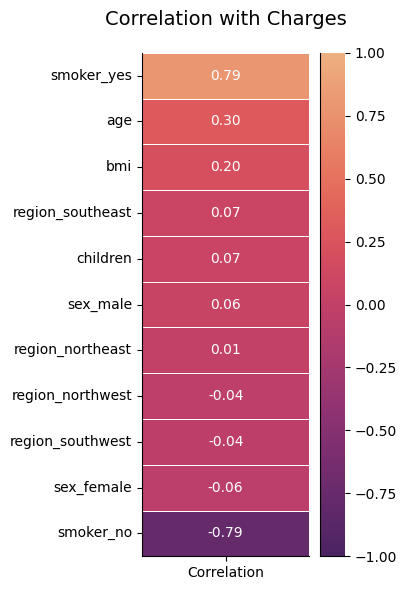

In [25]:
# Correlation
plt.figure(figsize=(4, 6))

charges_corr = (
    df_encoded.corr(numeric_only=True)["charges"]
    .drop('charges')
    .sort_values(ascending=False)
)

sns.heatmap(
    charges_corr.to_frame(name="Correlation"),
    annot=True,
    fmt=".2f",
    cmap="flare_r",
    vmin=-1, vmax=1, center=0,
    linewidths=0.5,
    cbar=True
)

plt.title("Correlation with Charges", fontsize=14, pad=20)

sns.despine()
plt.tight_layout()
plt.show()

In [27]:
# Total Charges by Smoker
charges_summary = (
    processed_df
    .groupby("smoker")["charges"]
    .agg(["sum"])
    .reset_index()
)

charges_summary["percentage"] = (
    charges_summary["sum"] / charges_summary["sum"].sum() * 100
).round(2)

display(charges_summary)

C:\Users\markg\AppData\Local\Temp\ipykernel_15024\1805796149.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("smoker")["charges"]


,smoker,sum,percentage
0,no,8.972422e+06,50.54
1,yes,8.781764e+06,49.46


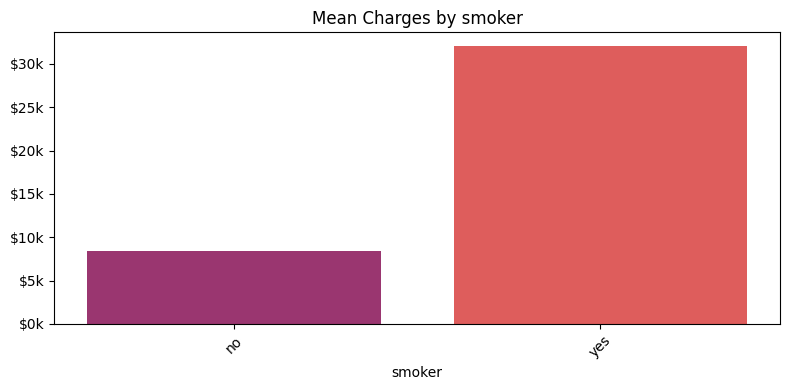

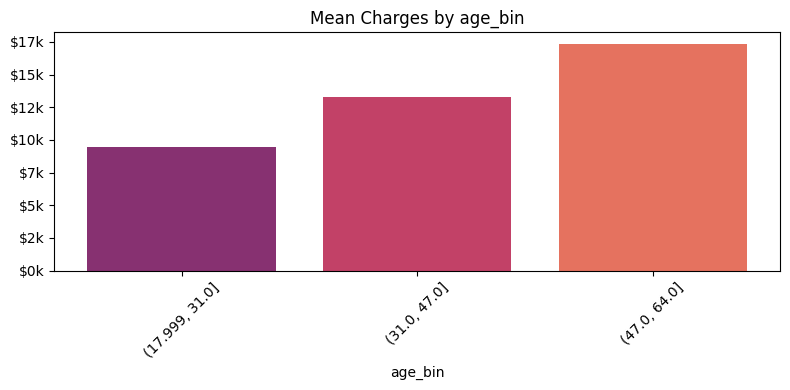

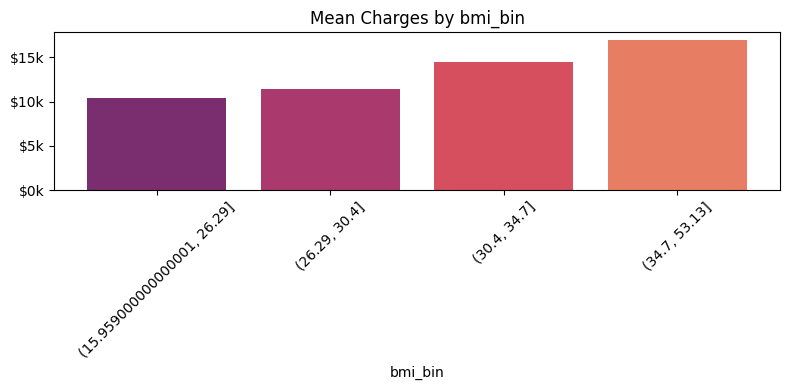

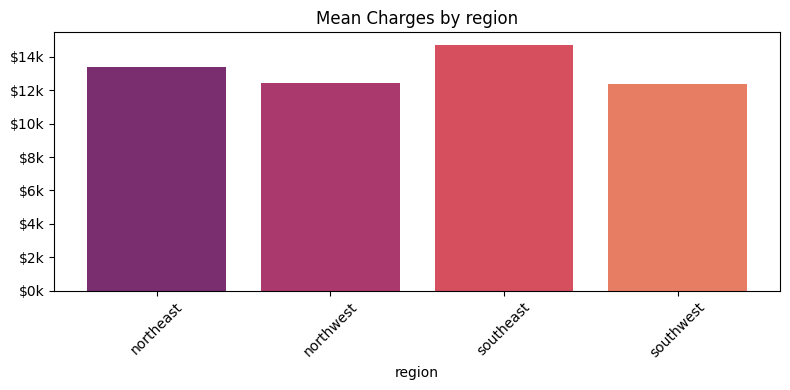

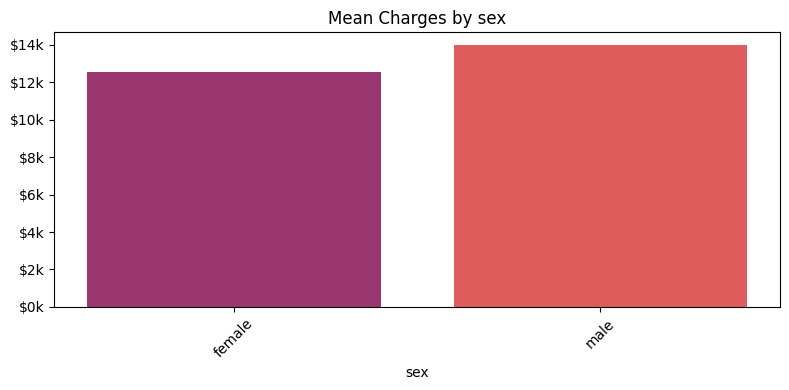

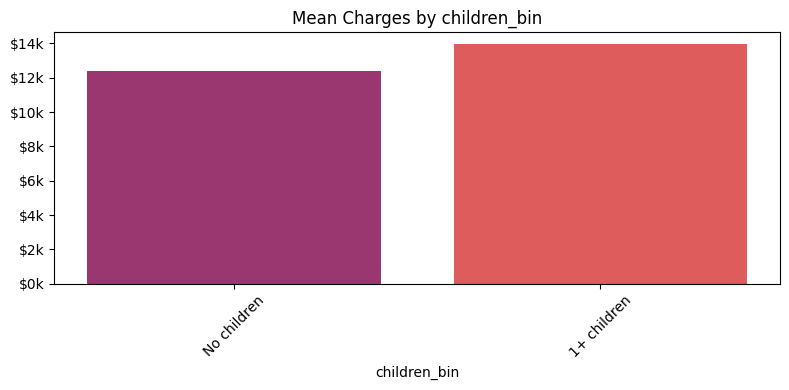

In [28]:
# Mean charges by groups
df_groups = processed_df.assign(
    age_bin=lambda x: pd.qcut(
        x["age"],
        q=3
    ),

    bmi_bin=lambda x: pd.qcut(
        x["bmi"],
        q=4
    ),

    children_bin=lambda x: pd.cut(
        x["children"],
        bins=[-0.5, 0.5, float("inf")],
        labels=["No children", "1+ children"]
    )
)

features = [
    "smoker",
    "age_bin",
    "bmi_bin",
    "region",
    "sex",
    "children_bin"
]

for col in features:
    mean_charges = (
        df_groups
        .groupby(col, observed=True)["charges"]
        .mean()
    )

    colors = sns.color_palette("flare_r", n_colors=len(mean_charges))
    plt.figure(figsize=(8, 4))

    plt.bar(
        mean_charges.index.astype(str),
        mean_charges.values,
        color=colors
    )

    plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}k'))
    plt.xlabel(col)
    plt.title(f"Mean Charges by {col}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

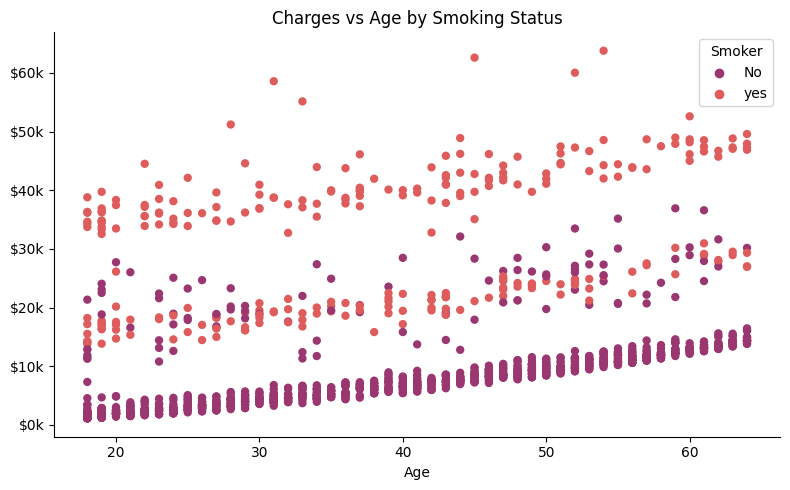

In [29]:
# Charges vs Age by Smoking Status
plt.figure(figsize=(8, 5))

sns.scatterplot(x='age', y='charges', data=processed_df, hue='smoker', hue_order=["no", "yes"], palette='flare_r', edgecolor='none')

handles, labels = plt.gca().get_legend_handles_labels()
new_labels = ['No' if label == 'no' else 'yes' for label in labels]
plt.legend(handles, new_labels, title='Smoker', loc='upper right')

plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}k'))

plt.title('Charges vs Age by Smoking Status')
plt.xlabel('Age')
plt.ylabel('')

sns.despine()
plt.tight_layout()
plt.show()

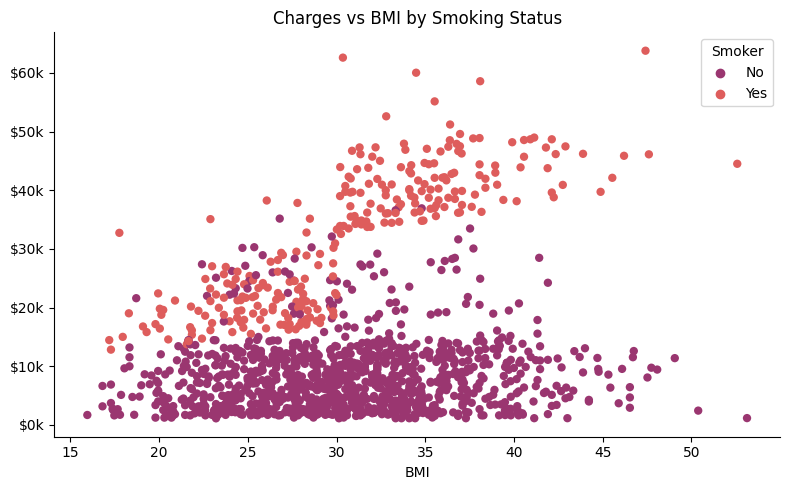

In [30]:
# Charges vs BMI by Smoking Status
plt.figure(figsize=(8, 5))

sns.scatterplot(x='bmi', y='charges', data=processed_df, hue='smoker', hue_order=["no", "yes"], palette='flare_r', edgecolor='none')

handles, labels = plt.gca().get_legend_handles_labels()
new_labels = ['No' if label == 'no' else 'Yes' for label in labels]
plt.legend(handles, new_labels, title='Smoker', loc='upper right')

plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}k'))

plt.title('Charges vs BMI by Smoking Status')
plt.xlabel('BMI')
plt.ylabel('')

sns.despine()
plt.tight_layout()
plt.show()

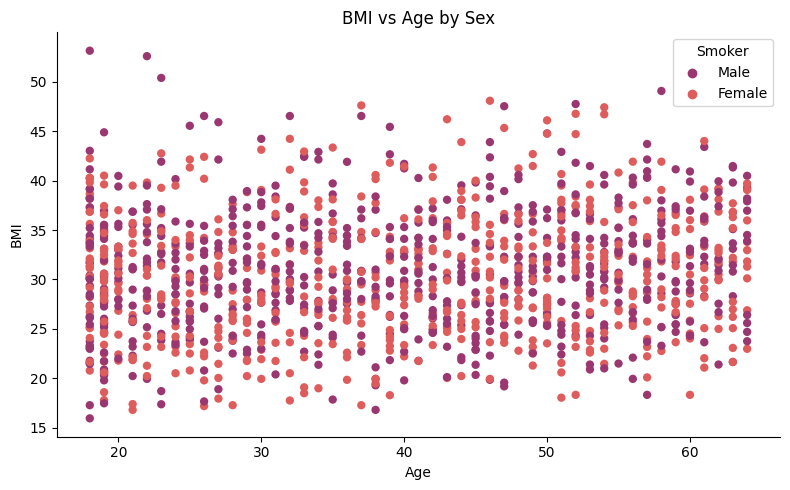

In [31]:
# BMI vs Age by Sex
plt.figure(figsize=(8, 5))

sns.scatterplot(x='age', y='bmi', data=processed_df, hue='sex', hue_order=["male", "female"], palette='flare_r', edgecolor='none')

handles, labels = plt.gca().get_legend_handles_labels()
new_labels = ['Male' if label == 'male' else 'Female' for label in labels]
plt.legend(handles, new_labels, title='Smoker', loc='upper right')

plt.title('BMI vs Age by Sex')
plt.xlabel('Age')
plt.ylabel('BMI')

sns.despine()
plt.tight_layout()
plt.show()